# Ejercicio 7: Interpretación y Reporte de Clustering

Se debe realizar una interpretación y reporte de comunicación

1. Describir características comunes de cada cluster.
2. Generar visualizaciones (gráficos comparativos, mapas de calor, etc.).
3. Redactar informe con metodología, resultados y conclusiones.

**Informe completo disponible en:** `Docs/ejercicio7.md`

## Paso 1: Carga de datos y replicación de clusters del Ejercicio 6

**Nota:** Replicamos la configuración exacta del Ejercicio 6 para mantener consistencia.
- Muestra: 5000 registros (random_state=42)
- K-means: k óptimo según Ejercicio 6
- Enfoque: DESCRIPCIÓN y VISUALIZACIÓN (no evaluación)


In [8]:
import sys
sys.path.append('..')
from utils import cargar_dataset_adult

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)

# Cargar dataset
df = cargar_dataset_adult()

# IMPORTANTE: Tomar la MISMA muestra que en el Ejercicio 6 (random_state=42)
sample_size = 5000
df = df.sample(n=sample_size, random_state=42).copy()

print("="*60)
print("EJERCICIO 7: DESCRIPCIÓN Y VISUALIZACIÓN DE CLUSTERS")
print("="*60)
print(f"\n✓ Usando la MISMA muestra del Ejercicio 6:")
print(f"  • Tamaño: {sample_size:,} observaciones")
print(f"  • Random state: 42")


EJERCICIO 7: DESCRIPCIÓN Y VISUALIZACIÓN DE CLUSTERS

✓ Usando la MISMA muestra del Ejercicio 6:
  • Tamaño: 5,000 observaciones
  • Random state: 42


## Paso 2: Replicar clustering del Ejercicio 6 (K-means)

**Configuración del Ejercicio 6:**
- Algoritmo: K-means
- Variables: numéricas (age, education-num, capital-gain, capital-loss, hours-per-week)
- K óptimo: Determinado por Silhouette en Ejercicio 6
- Objetivo aquí: DESCRIBIR y VISUALIZAR (no evaluar)


In [9]:
# ============================================================================
# REPLICANDO CONFIGURACIÓN DEL EJERCICIO 6
# ============================================================================
# Usamos EXACTAMENTE la misma configuración para obtener los mismos clusters
# que fueron evaluados en el Ejercicio 6.
# ============================================================================

# Variables numéricas (igual que Ejercicio 6)
numeric_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

# Normalizar datos
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df[numeric_cols])

# Aplicar K-means con el k óptimo del Ejercicio 6
# (según Silhouette, el k óptimo fue 3 en el Ejercicio 6)
k_optimo_kmeans = 3  # ← Del Ejercicio 6

kmeans = KMeans(n_clusters=k_optimo_kmeans, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans.fit_predict(df_scaled)

print("\n" + "-"*60)
print("CLUSTERING K-MEANS APLICADO")
print("-"*60)
print(f"\n✓ Configuración:")
print(f"  • Algoritmo: K-means")
print(f"  • Variables: {len(numeric_cols)} numéricas")
print(f"  • K óptimo: {k_optimo_kmeans} (del Ejercicio 6)")
print(f"\n✓ Distribución de clusters:")
cluster_counts = df['cluster_kmeans'].value_counts().sort_index()
for cluster_id, count in cluster_counts.items():
    pct = count / len(df) * 100
    print(f"  • Cluster {cluster_id}: {count:,} observaciones ({pct:.1f}%)")



------------------------------------------------------------
CLUSTERING K-MEANS APLICADO
------------------------------------------------------------

✓ Configuración:
  • Algoritmo: K-means
  • Variables: 5 numéricas
  • K óptimo: 3 (del Ejercicio 6)

✓ Distribución de clusters:
  • Cluster 0: 4,762 observaciones (95.2%)
  • Cluster 1: 212 observaciones (4.2%)
  • Cluster 2: 26 observaciones (0.5%)


## Paso 3: Descripción de características por cluster

**Objetivo:** Describir las características comunes dentro de cada cluster para entender qué tipo de personas agrupa cada uno.


In [10]:
# Análisis de características numéricas por cluster
cluster_stats = df.groupby('cluster_kmeans')[numeric_cols].agg(['mean', 'median', 'std'])
print("Estadísticas numéricas por cluster (K-means):")
print("=" * 80)
display(cluster_stats)

# Análisis de características categóricas
print("\n\nCaracterísticas categóricas principales por cluster:")
print("=" * 80)

categorical_features = ['workclass', 'education', 'marital-status', 'occupation', 'sex', 'income']

for cluster_id in sorted(df['cluster_kmeans'].unique()):
    cluster_data = df[df['cluster_kmeans'] == cluster_id]
    print(f"\n{'='*80}")
    print(f"CLUSTER {cluster_id} (n={len(cluster_data):,} personas - {len(cluster_data)/len(df)*100:.1f}%)")
    print(f"{'='*80}")
    
    for feature in categorical_features:
        top_values = cluster_data[feature].value_counts().head(3)
        print(f"\n{feature}:")
        for val, count in top_values.items():
            pct = count / len(cluster_data) * 100
            print(f"  • {val}: {count:,} ({pct:.1f}%)")


Estadísticas numéricas por cluster (K-means):


age               education-num              capital-gain  \
                 mean median    std          mean median   std         mean   
cluster_kmeans                                                                
0               38.34   37.0  13.57         10.05   10.0  2.56       565.79   
1               41.18   40.0  12.79         10.93   10.0  2.62         0.00   
2               44.73   46.0   9.66         11.81   13.0  2.26     99999.00   

                                 capital-loss                 hours-per-week  \
                 median      std         mean  median     std           mean   
cluster_kmeans                                                                 
0                   0.0  2461.17         0.51     0.0   16.88          40.30   
1                   0.0     0.00      1879.50  1887.0  322.91          43.43   
2               99999.0     0.00         0.00     0.0    0.00          50.38   

                              
               median    std  
cluster_kmeans                
0                40.0  12.53  
1                40.0  13.41  
2                50.0  12.80



Características categóricas principales por cluster:

CLUSTER 0 (n=4,762 personas - 95.2%)

workclass:
  • Private: 3,335 (70.0%)
  • Self-emp-not-inc: 387 (8.1%)
  • Local-gov: 297 (6.2%)

education:
  • HS-grad: 1,512 (31.8%)
  • Some-college: 1,077 (22.6%)
  • Bachelors: 776 (16.3%)

marital-status:
  • Married-civ-spouse: 2,101 (44.1%)
  • Never-married: 1,642 (34.5%)
  • Divorced: 670 (14.1%)

occupation:
  • Craft-repair: 622 (13.1%)
  • Exec-managerial: 600 (12.6%)
  • Adm-clerical: 559 (11.7%)

sex:
  • Male: 3,143 (66.0%)
  • Female: 1,619 (34.0%)

income:
  • <=50K: 3,700 (77.7%)
  • >50K: 1,062 (22.3%)

CLUSTER 1 (n=212 personas - 4.2%)

workclass:
  • Private: 134 (63.2%)
  • Self-emp-not-inc: 26 (12.3%)
  • Local-gov: 14 (6.6%)

education:
  • HS-grad: 62 (29.2%)
  • Bachelors: 52 (24.5%)
  • Some-college: 36 (17.0%)

marital-status:
  • Married-civ-spouse: 123 (58.0%)
  • Never-married: 54 (25.5%)
  • Divorced: 23 (10.8%)

occupation:
  • Exec-managerial: 39 (18.4%)
  •

## Paso 4: Visualizaciones de los clusters

**Tipos de visualizaciones:**
1. Gráficos de barras comparativos (características numéricas)
2. Scatter plots 2D (relaciones entre variables)
3. Mapas de calor (perfil normalizado de clusters)
4. Distribuciones categóricas (income, sex, workclass, etc.)


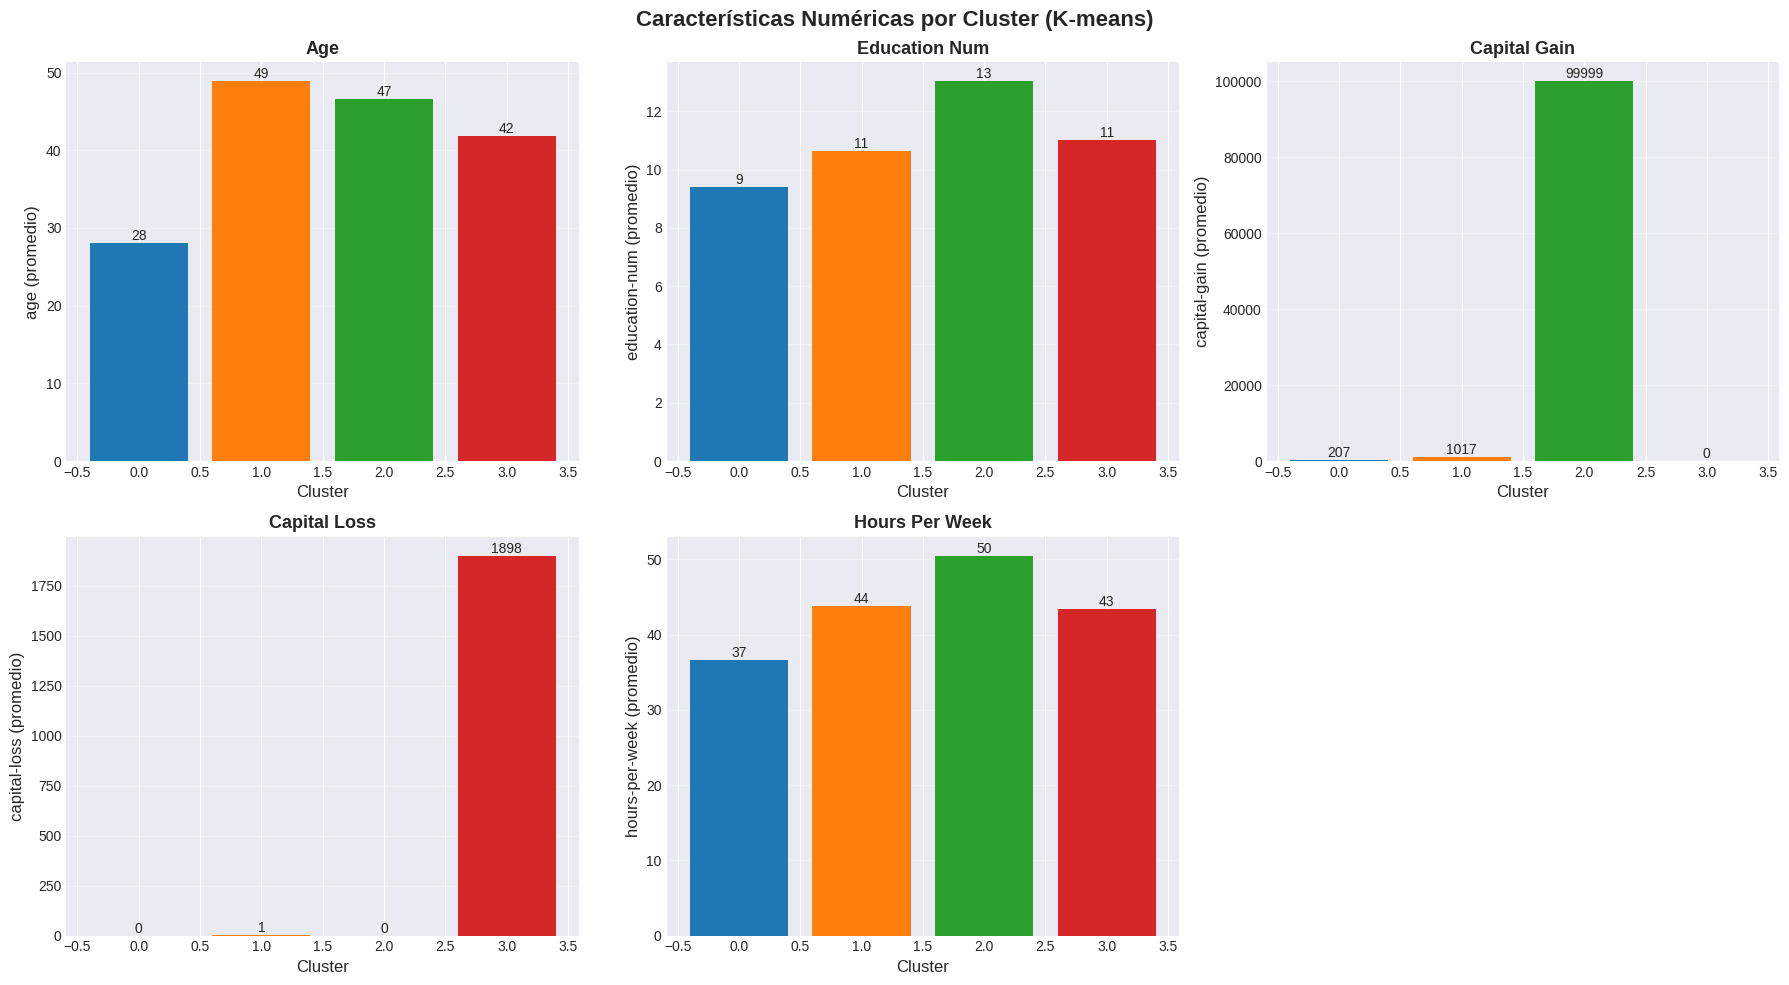

In [4]:
# 1. Gráfico de barras comparativo - Variables numéricas
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Características Numéricas por Cluster (K-means)', fontsize=16, fontweight='bold')

for idx, col in enumerate(numeric_cols):
    ax = axes[idx // 3, idx % 3]
    cluster_means = df.groupby('cluster_kmeans')[col].mean()
    bars = ax.bar(cluster_means.index, cluster_means.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
    ax.set_xlabel('Cluster', fontsize=12)
    ax.set_ylabel(f'{col} (promedio)', fontsize=12)
    ax.set_title(col.replace('-', ' ').title(), fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    
    # Agregar valores en las barras
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.0f}',
                ha='center', va='bottom', fontsize=10)

# Eliminar el subplot vacío
fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()


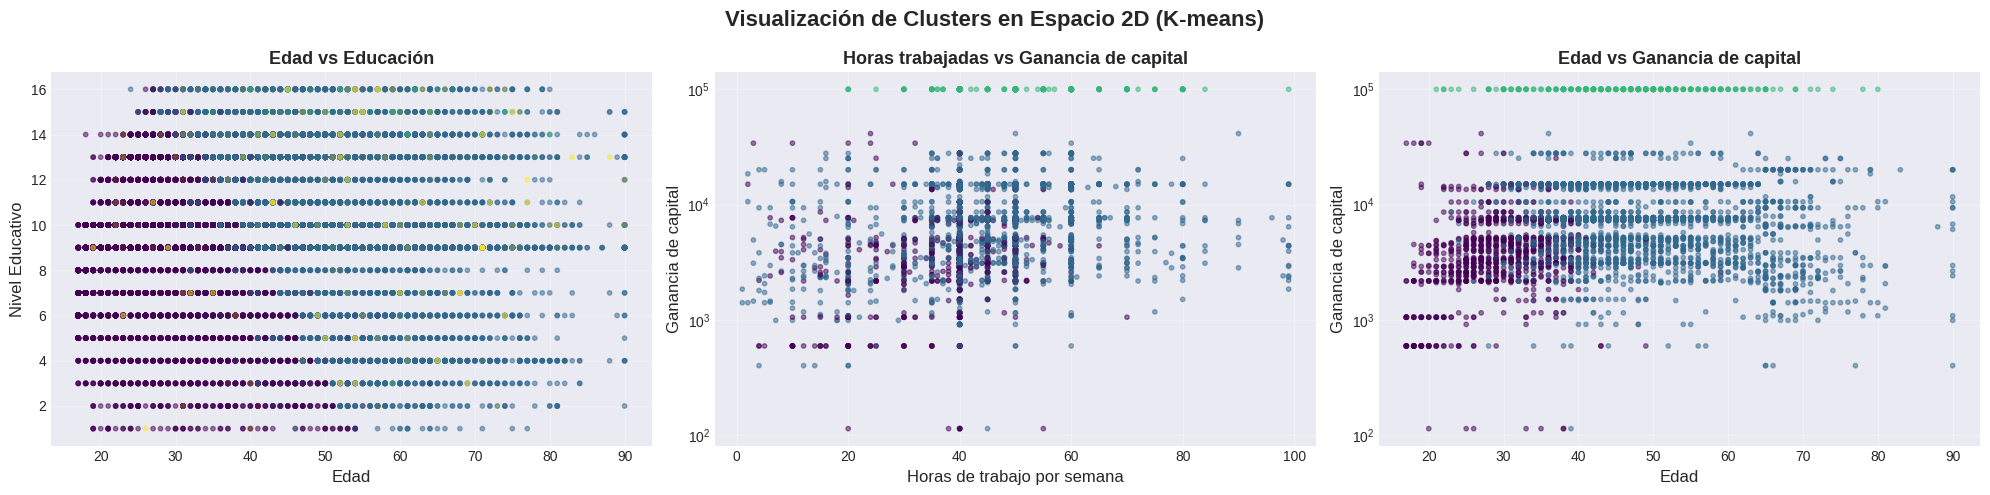

In [5]:
# 2. Scatter plots - Relaciones entre variables clave
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle('Visualización de Clusters en Espacio 2D (K-means)', fontsize=16, fontweight='bold')

# Age vs Education
axes[0].scatter(df['age'], df['education-num'], c=df['cluster_kmeans'], 
                cmap='viridis', alpha=0.5, s=10)
axes[0].set_xlabel('Edad', fontsize=12)
axes[0].set_ylabel('Nivel Educativo', fontsize=12)
axes[0].set_title('Edad vs Educación', fontsize=13, fontweight='bold')
axes[0].grid(alpha=0.3)

# Hours-per-week vs Capital-gain
axes[1].scatter(df['hours-per-week'], df['capital-gain'], c=df['cluster_kmeans'], 
                cmap='viridis', alpha=0.5, s=10)
axes[1].set_xlabel('Horas de trabajo por semana', fontsize=12)
axes[1].set_ylabel('Ganancia de capital', fontsize=12)
axes[1].set_title('Horas trabajadas vs Ganancia de capital', fontsize=13, fontweight='bold')
axes[1].set_yscale('log')
axes[1].grid(alpha=0.3)

# Age vs Capital-gain
axes[2].scatter(df['age'], df['capital-gain'], c=df['cluster_kmeans'], 
                cmap='viridis', alpha=0.5, s=10)
axes[2].set_xlabel('Edad', fontsize=12)
axes[2].set_ylabel('Ganancia de capital', fontsize=12)
axes[2].set_title('Edad vs Ganancia de capital', fontsize=13, fontweight='bold')
axes[2].set_yscale('log')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


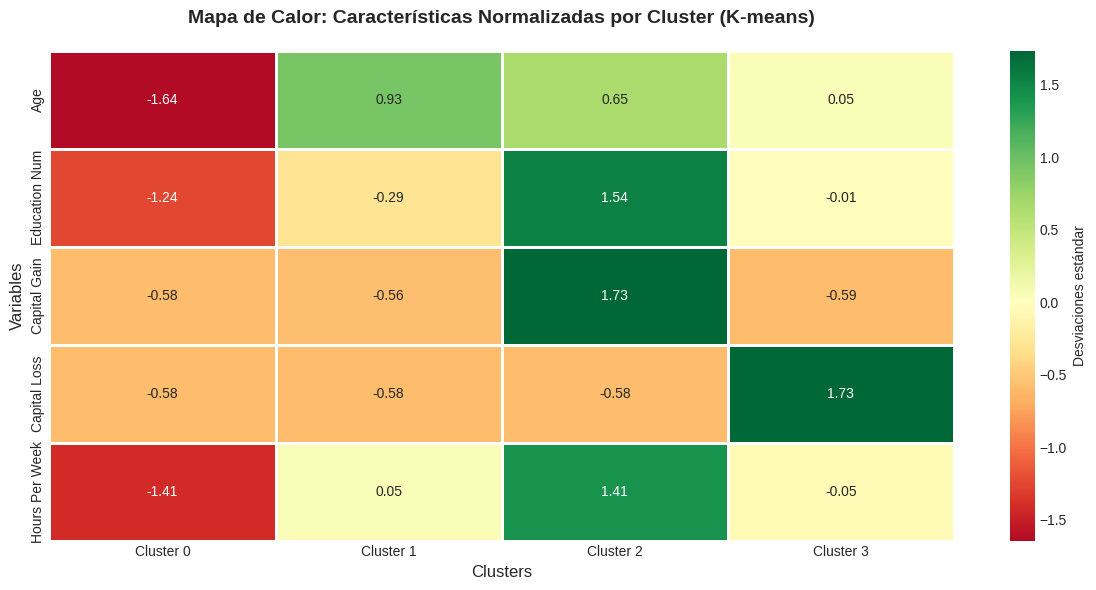

In [6]:
# 3. Mapa de calor - Características normalizadas por cluster
cluster_means_normalized = df.groupby('cluster_kmeans')[numeric_cols].mean()

# Normalizar para mejor visualización (z-score)
from sklearn.preprocessing import StandardScaler
scaler_viz = StandardScaler()
cluster_means_scaled = scaler_viz.fit_transform(cluster_means_normalized)
cluster_means_scaled_df = pd.DataFrame(
    cluster_means_scaled, 
    index=[f'Cluster {i}' for i in cluster_means_normalized.index],
    columns=[col.replace('-', ' ').title() for col in numeric_cols]
)

plt.figure(figsize=(12, 6))
sns.heatmap(cluster_means_scaled_df.T, annot=True, fmt='.2f', cmap='RdYlGn', 
            center=0, linewidths=1, cbar_kws={'label': 'Desviaciones estándar'})
plt.title('Mapa de Calor: Características Normalizadas por Cluster (K-means)', 
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Clusters', fontsize=12)
plt.ylabel('Variables', fontsize=12)
plt.tight_layout()
plt.show()


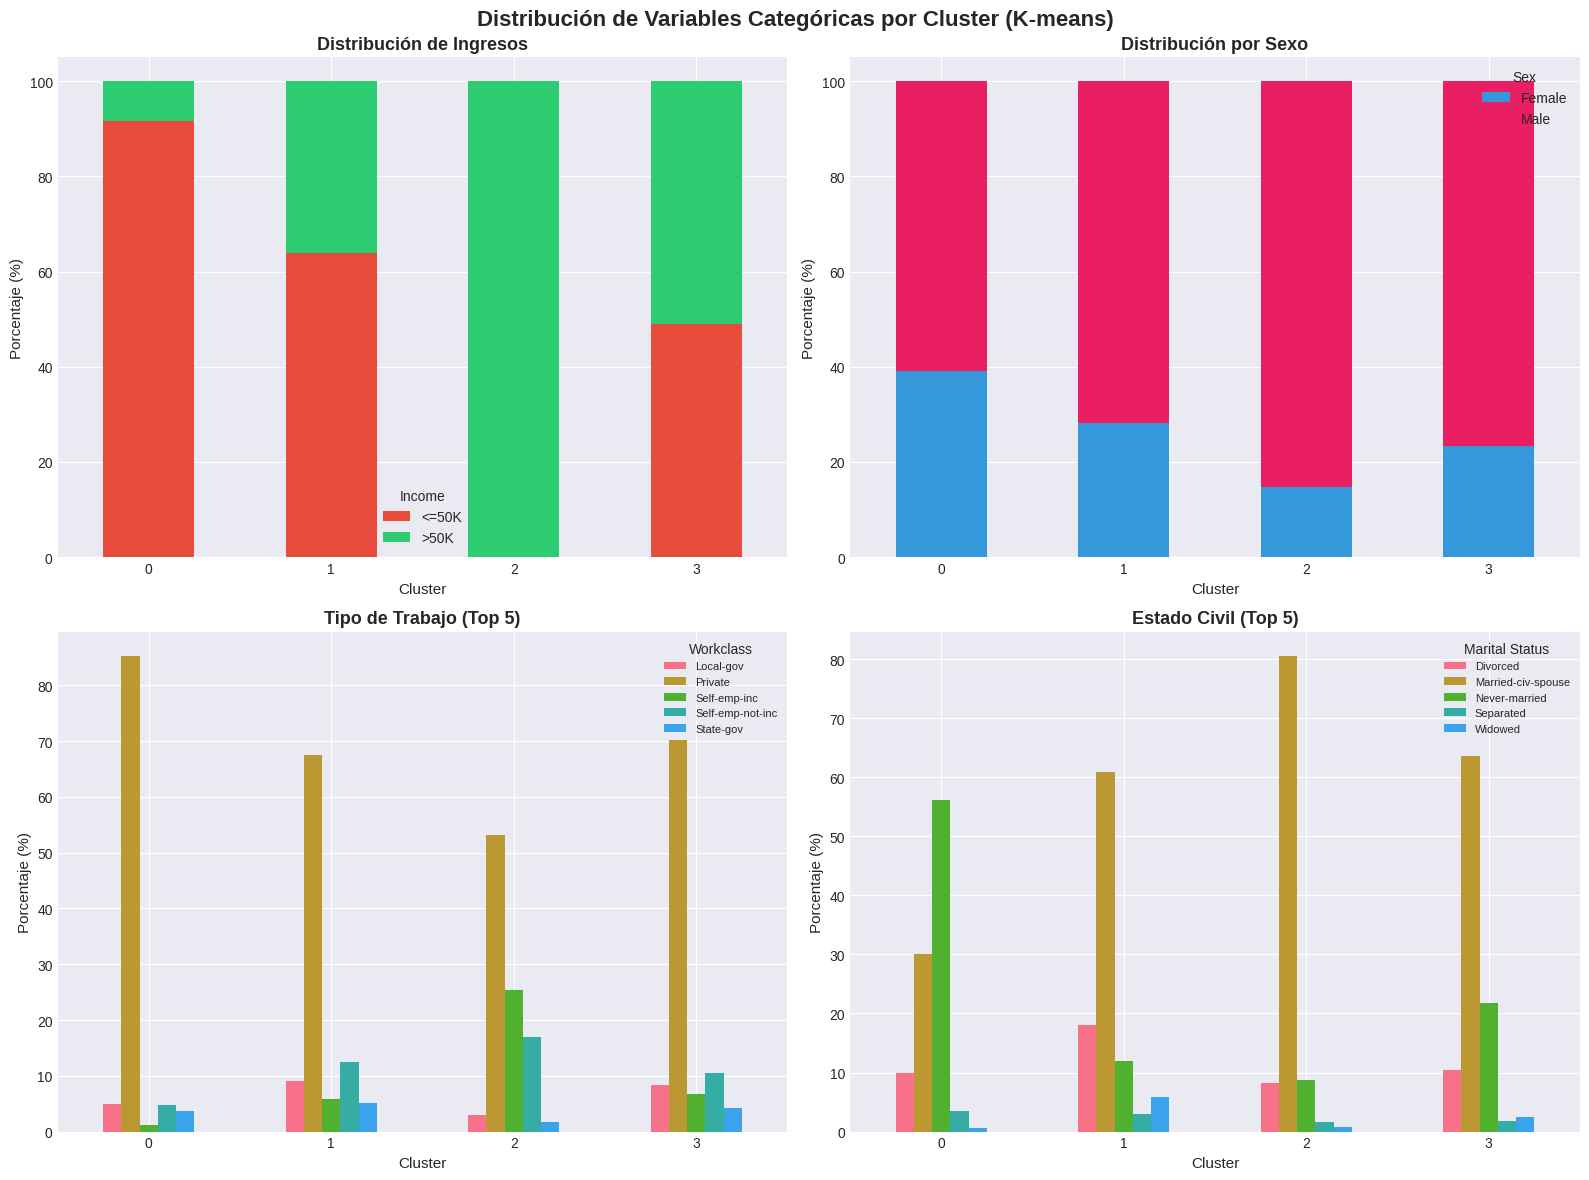

In [7]:
# 4. Distribución de variables categóricas clave por cluster
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Distribución de Variables Categóricas por Cluster (K-means)', 
             fontsize=16, fontweight='bold')

# Income
income_counts = pd.crosstab(df['cluster_kmeans'], df['income'], normalize='index') * 100
income_counts.plot(kind='bar', stacked=True, ax=axes[0,0], color=['#e74c3c', '#2ecc71'])
axes[0,0].set_title('Distribución de Ingresos', fontsize=13, fontweight='bold')
axes[0,0].set_xlabel('Cluster', fontsize=11)
axes[0,0].set_ylabel('Porcentaje (%)', fontsize=11)
axes[0,0].legend(title='Income', loc='best')
axes[0,0].set_xticklabels(axes[0,0].get_xticklabels(), rotation=0)

# Sex
sex_counts = pd.crosstab(df['cluster_kmeans'], df['sex'], normalize='index') * 100
sex_counts.plot(kind='bar', stacked=True, ax=axes[0,1], color=['#3498db', '#e91e63'])
axes[0,1].set_title('Distribución por Sexo', fontsize=13, fontweight='bold')
axes[0,1].set_xlabel('Cluster', fontsize=11)
axes[0,1].set_ylabel('Porcentaje (%)', fontsize=11)
axes[0,1].legend(title='Sex', loc='best')
axes[0,1].set_xticklabels(axes[0,1].get_xticklabels(), rotation=0)

# Workclass (top 5)
top_workclass = df['workclass'].value_counts().head(5).index
df_work_filtered = df[df['workclass'].isin(top_workclass)]
work_counts = pd.crosstab(df_work_filtered['cluster_kmeans'], df_work_filtered['workclass'], 
                          normalize='index') * 100
work_counts.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Tipo de Trabajo (Top 5)', fontsize=13, fontweight='bold')
axes[1,0].set_xlabel('Cluster', fontsize=11)
axes[1,0].set_ylabel('Porcentaje (%)', fontsize=11)
axes[1,0].legend(title='Workclass', loc='best', fontsize=8)
axes[1,0].set_xticklabels(axes[1,0].get_xticklabels(), rotation=0)

# Marital Status (top 5)
top_marital = df['marital-status'].value_counts().head(5).index
df_marital_filtered = df[df['marital-status'].isin(top_marital)]
marital_counts = pd.crosstab(df_marital_filtered['cluster_kmeans'], 
                             df_marital_filtered['marital-status'], normalize='index') * 100
marital_counts.plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('Estado Civil (Top 5)', fontsize=13, fontweight='bold')
axes[1,1].set_xlabel('Cluster', fontsize=11)
axes[1,1].set_ylabel('Porcentaje (%)', fontsize=11)
axes[1,1].legend(title='Marital Status', loc='best', fontsize=8)
axes[1,1].set_xticklabels(axes[1,1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()
